# When Outliers Matter: Investigating Gradient-Based Data Selection Under Spurious Correlations

**UCLA CS 260D — Final Project | Fall 2026**

## 7. Experiment 6: Deep Feature Reweighting (DFR)

### 7.1 Introduction

**Deep Feature Reweighting (DFR)** (Kirichenko et al., 2023) argues that a network trained with ERM often already *contains* the core features needed to classify minority groups; what goes wrong is the **last layer**, which learns to rely on the spurious feature. DFR therefore keeps the feature extractor fixed and **retrains only the final linear layer on a small group-balanced dataset**.

In our setting the ResNet-18 backbone is already frozen for every method, so DFR reduces to: *train a new `Linear(512, 2)` head on a group-balanced subset of the cached features*.

Unlike ERM, EPIC-inspired filtering, random filtering, and JTT, **DFR uses group annotations** (to build the balanced subset and to tune hyperparameters on validation worst-group accuracy). It should therefore be compared with Group DRO, the other group-aware method.

**Differences from the original DFR (documented as required by the shared protocol):**

| | Original DFR | Our DFR |
|---|---|---|
| Feature extractor | Fine-tuned on the task with ERM | ImageNet ResNet-18, frozen (shared protocol) |
| Reweighting data | Group-balanced half of the **validation** set | Group-balanced subset of the **training** split (README: do not train on validation) |
| Classifier | L1-regularized logistic regression (scikit-learn) | `Linear(512, 2)` + Adam + weight decay (shared protocol) |
| Ensembling | Weights averaged over 10 balanced subsets | Reported both as a single subset and as a 10-subset ensemble |
| Feature preprocessing | Standardized | Standardized (selected on validation; see 7.7) |

Because the backbone was never trained on CelebA, our experiment is closest to the paper's **DFR<sup>Tr</sup><sub>Tr</sub>** variant (balanced retraining on training data). It isolates the question: *how much of ERM's worst-group failure is caused by the classifier head rather than the representation?*

### 7.2 Environment and Configuration

Load the cached ResNet-18 features from `erm_celeba.ipynb`. Run `explore_celeba.ipynb` and the feature-extraction sections of `erm_celeba.ipynb` first if `data/processed/features/` is missing.

Shared protocol settings (Adam, lr 1e-3, batch size 512, seeds 42 / 123 / 2026, checkpoint selection by minimum validation loss) are kept. Because the balanced subset is ~29x smaller than the full training set, we train for 100 epochs instead of 20 so the head converges; the best epoch is still chosen by validation loss.

In [1]:
# ============================================================
# 7.2 Environment and configuration
# ============================================================

import copy
import json
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# ------------------------------------------------------------
# 1. Hardware accelerator
# ------------------------------------------------------------

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


# ------------------------------------------------------------
# 2. Paths
# ------------------------------------------------------------

FEATURE_DIR = Path("data/processed/features")
MODEL_DIR = Path("results/models")
METRICS_DIR = Path("results/metrics")
FIGURE_DIR = Path("results/figures")

for directory in (MODEL_DIR, METRICS_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 3. Experimental configuration
# ------------------------------------------------------------

SEED = 42
EVAL_SEEDS = [42, 123, 2026]

LEARNING_RATE = 1e-3
BATCH_SIZE = 512
EPOCHS = 100                 # small balanced subset -> more epochs
N_ENSEMBLE = 10              # balanced subsets averaged in DFR ensemble

# Hyperparameter grid (selected by mean validation WGA over seeds)
WEIGHT_DECAY_GRID = [0.0, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]
STANDARDIZE_GRID = [False, True]

GROUP_NAMES = {
    0: "Non-blond / Non-male",
    1: "Non-blond / Male",
    2: "Blond / Non-male",
    3: "Blond / Male",
}

set_seed(SEED)

print("=" * 50)
print("CelebA DFR — Environment")
print("=" * 50)
print(f"PyTorch: {torch.__version__}")
print(f"Device: {device}")
print(f"Seeds: {EVAL_SEEDS}")
print(f"Epochs: {EPOCHS} | Batch size: {BATCH_SIZE} | LR: {LEARNING_RATE}")

CelebA DFR — Environment
PyTorch: 2.14.1+cu126
Device: cuda
Seeds: [42, 123, 2026]
Epochs: 100 | Batch size: 512 | LR: 0.001


### 7.3 Load Cached Features and the Multi-Seed ERM Reference

Load the frozen ResNet-18 features, labels, and group IDs for all three splits.

For a like-for-like comparison, the ERM reference is **re-trained here for seeds 42 / 123 / 2026** with exactly the multi-seed ERM procedure of `epic_celeba.ipynb` (section 3.9): full training set, raw features, Adam (lr 1e-3, weight decay 1e-4), batch size 512 with a seeded shuffle, 20 epochs, checkpoint by minimum validation loss. The team's saved reference (`results/metrics/epic_multiseed_10pct_summary.csv`) is printed alongside; small differences are expected across hardware.

In [2]:
# ============================================================
# 7.3 Load cached features and ERM reference
# ============================================================

def load_split(split):
    features = np.load(FEATURE_DIR / f"{split}_features.npy")
    labels = np.load(FEATURE_DIR / f"{split}_labels.npy")
    groups = np.load(FEATURE_DIR / f"{split}_groups.npy")
    return features.astype(np.float32), labels, groups


X_train, y_train, g_train = load_split("train")
X_val, y_val, g_val = load_split("val")
X_test, y_test, g_test = load_split("test")

assert X_train.shape == (162770, 512)
assert X_val.shape == (19867, 512)
assert X_test.shape == (19962, 512)
assert np.all(g_train // 2 == y_train)

# ------------------------------------------------------------
# Evaluation helpers
# ------------------------------------------------------------

def predict(model, X, mean, std):
    model.eval()
    X = torch.from_numpy((X - mean) / std).float()
    predictions = []
    with torch.inference_mode():
        for start in range(0, len(X), 4096):
            logits = model(X[start:start + 4096].to(device))
            predictions.append(logits.argmax(dim=1).cpu().numpy())
    return np.concatenate(predictions)


def evaluate(model, X, y, g, mean=0.0, std=1.0):
    predictions = predict(model, X, mean, std)
    group_acc = {
        k: float((predictions[g == k] == y[g == k]).mean() * 100)
        for k in range(4)
    }
    return {
        "overall_accuracy": float((predictions == y).mean() * 100),
        "worst_group_accuracy": min(group_acc.values()),
        "worst_group": int(min(group_acc, key=group_acc.get)),
        "group_accuracies": group_acc,
    }

# ------------------------------------------------------------
# Multi-seed ERM reference (same procedure as epic_celeba.ipynb 3.9)
# ------------------------------------------------------------

from torch.utils.data import DataLoader, TensorDataset

X_train_t = torch.from_numpy(X_train)
y_train_t = torch.from_numpy(y_train).long()
X_val_t = torch.from_numpy(X_val)
y_val_t = torch.from_numpy(y_val).long()


def train_erm_reference(seed, epochs=20):
    torch.manual_seed(seed)
    np.random.seed(seed)

    model = nn.Linear(512, 2).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()

    loader = DataLoader(
        TensorDataset(X_train_t, y_train_t), batch_size=512, shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )
    val_loader = DataLoader(
        TensorDataset(X_val_t, y_val_t), batch_size=1024, shuffle=False
    )

    best_loss, best_state = float("inf"), None
    for epoch in range(epochs):
        model.train()
        for features, labels in loader:
            features, labels = features.to(device), labels.to(device)
            optimizer.zero_grad()
            criterion(model(features), labels).backward()
            optimizer.step()

        model.eval()
        val_loss_sum = 0.0
        with torch.inference_mode():
            for features, labels in val_loader:
                features, labels = features.to(device), labels.to(device)
                val_loss_sum += criterion(model(features), labels).item() * len(labels)
        if val_loss_sum / len(X_val) < best_loss:
            best_loss = val_loss_sum / len(X_val)
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    model.eval()
    return model


erm_runs = {}
start = time.perf_counter()
for seed in EVAL_SEEDS:
    seed_start = time.perf_counter()
    model = train_erm_reference(seed)
    erm_runs[seed] = {
        "val": evaluate(model, X_val, y_val, g_val),
        "test": evaluate(model, X_test, y_test, g_test),
        "seconds": time.perf_counter() - seed_start,
    }
erm_time = time.perf_counter() - start


def mean_result(split):
    # Seed-averaged ERM metrics (used for reference lines in plots).
    runs = [erm_runs[s][split] for s in EVAL_SEEDS]
    return {
        "overall_accuracy": float(np.mean([r["overall_accuracy"] for r in runs])),
        "worst_group_accuracy": float(np.mean([r["worst_group_accuracy"] for r in runs])),
        "group_accuracies": {
            k: float(np.mean([r["group_accuracies"][k] for r in runs])) for k in range(4)
        },
    }


erm_val, erm_test = mean_result("val"), mean_result("test")

erm_table = pd.DataFrame([
    {"Seed": s,
     "Val overall (%)": erm_runs[s]["val"]["overall_accuracy"],
     "Val WGA (%)": erm_runs[s]["val"]["worst_group_accuracy"],
     "Test overall (%)": erm_runs[s]["test"]["overall_accuracy"],
     "Test WGA (%)": erm_runs[s]["test"]["worst_group_accuracy"]}
    for s in EVAL_SEEDS
]).round(2)

print("ERM reference, retrained locally (seeds 42 / 123 / 2026)")
print(erm_table.to_string(index=False))
print(f"\nMean val:  overall {erm_val['overall_accuracy']:.2f}% | "
      f"WGA {erm_val['worst_group_accuracy']:.2f}% "
      f"(std {erm_table['Val WGA (%)'].std():.2f})")
print(f"Mean test: overall {erm_test['overall_accuracy']:.2f}% | "
      f"WGA {erm_test['worst_group_accuracy']:.2f}%")
print(f"Training time: {erm_time / len(EVAL_SEEDS):.1f} s per seed")

team_reference = METRICS_DIR / "epic_multiseed_10pct_summary.csv"
if team_reference.is_file():
    team = pd.read_csv(team_reference).set_index("Method").loc["ERM"]
    print(f"\nTeam reference (epic_celeba.ipynb, val): overall "
          f"{team['Overall_Mean']:.2f} ± {team['Overall_Std']:.2f}% | "
          f"WGA {team['Worst_Mean']:.2f} ± {team['Worst_Std']:.2f}%")

ERM reference, retrained locally (seeds 42 / 123 / 2026)
 Seed  Val overall (%)  Val WGA (%)  Test overall (%)  Test WGA (%)
   42            93.81        16.48             94.23         19.44
  123            93.80        15.38             94.27         20.00
 2026            93.81        15.93             94.29         20.56

Mean val:  overall 93.81% | WGA 15.93% (std 0.55)
Mean test: overall 94.26% | WGA 20.00%
Training time: 40.6 s per seed

Team reference (epic_celeba.ipynb, val): overall 93.81 ± 0.01% | WGA 15.75 ± 0.32%


### 7.4 Group-Balanced Retraining Set

DFR retrains the head on data in which **every group is equally represented**, removing the statistical shortcut `Male → Non-blond`. We subsample each training group (without replacement) down to the size of the smallest group, G3 (Blond / Male).

Validation and test sets are **not** modified.

In [3]:
# ============================================================
# 7.4 Group-balanced retraining set
# ============================================================

train_group_counts = np.bincount(g_train, minlength=4)
N_PER_GROUP = int(train_group_counts.min())


def balanced_indices(seed):
    rng = np.random.default_rng(seed)
    return np.concatenate([
        rng.choice(np.where(g_train == k)[0], N_PER_GROUP, replace=False)
        for k in range(4)
    ])


example_idx = balanced_indices(SEED)
balanced_counts = np.bincount(g_train[example_idx], minlength=4)

balance_df = pd.DataFrame({
    "Group": range(4),
    "Description": [GROUP_NAMES[k] for k in range(4)],
    "Full training set": train_group_counts,
    "Full share (%)": (train_group_counts / train_group_counts.sum() * 100).round(2),
    "Balanced subset": balanced_counts,
    "Balanced share (%)": (balanced_counts / balanced_counts.sum() * 100).round(2),
})

print(f"Examples per group: {N_PER_GROUP:,}")
print(f"Balanced subset size: {len(example_idx):,} "
      f"({len(example_idx) / len(g_train):.1%} of training data)\n")
print(balance_df.to_string(index=False))

Examples per group: 1,387
Balanced subset size: 5,548 (3.4% of training data)

 Group          Description  Full training set  Full share (%)  Balanced subset  Balanced share (%)
     0 Non-blond / Non-male              71629           44.01             1387                25.0
     1     Non-blond / Male              66874           41.08             1387                25.0
     2     Blond / Non-male              22880           14.06             1387                25.0
     3         Blond / Male               1387            0.85             1387                25.0


### 7.5 DFR Training

Train a freshly initialized `Linear(512, 2)` on the balanced subset. When standardization is enabled, features are centered and scaled using statistics of the retraining data (as in the original DFR) and the same transform is applied to validation and test features.

The best epoch is selected by minimum validation loss, as in ERM. `train_dfr` is reused for the hyperparameter search and the multi-seed evaluation.

In [4]:
# ============================================================
# 7.5 DFR training
# ============================================================

def train_dfr(indices, seed, weight_decay, standardize=True,
              epochs=EPOCHS, mean=None, std=None):
    # Train a new linear head on X_train[indices].
    X_sub, y_sub = X_train[indices], y_train[indices]

    if not standardize:
        mean, std = np.zeros(512, np.float32), np.ones(512, np.float32)
    elif mean is None:
        mean = X_sub.mean(axis=0)
        std = X_sub.std(axis=0) + 1e-8

    X_tr = torch.from_numpy((X_sub - mean) / std).float().to(device)
    y_tr = torch.from_numpy(y_sub).long().to(device)
    X_v = torch.from_numpy((X_val - mean) / std).float().to(device)
    y_v = torch.from_numpy(y_val).long().to(device)

    set_seed(seed)
    model = nn.Linear(512, 2).to(device)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LEARNING_RATE, weight_decay=weight_decay
    )
    criterion = nn.CrossEntropyLoss()
    shuffle = torch.Generator().manual_seed(seed)

    history = {"train_loss": [], "val_loss": [], "val_accuracy": []}
    best_val_loss, best_epoch, best_state = float("inf"), 0, None

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        for batch in torch.randperm(len(y_tr), generator=shuffle).split(BATCH_SIZE):
            batch = batch.to(device)
            optimizer.zero_grad()
            loss = criterion(model(X_tr[batch]), y_tr[batch])
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(batch)

        model.eval()
        with torch.inference_mode():
            logits = model(X_v)
            val_loss = criterion(logits, y_v).item()
            val_acc = (logits.argmax(1) == y_v).float().mean().item() * 100

        history["train_loss"].append(total_loss / len(y_tr))
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss, best_epoch = val_loss, epoch + 1
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    model.eval()
    return model, mean, std, history, best_epoch


# ------------------------------------------------------------
# Single run (seed 42, standardized, shared weight decay)
# ------------------------------------------------------------

start = time.perf_counter()
dfr_model, dfr_mean, dfr_std, dfr_history, dfr_best_epoch = train_dfr(
    balanced_indices(SEED), SEED, weight_decay=1e-4, standardize=True
)
single_run_time = time.perf_counter() - start

single_val = evaluate(dfr_model, X_val, y_val, g_val, dfr_mean, dfr_std)

print(f"Best epoch: {dfr_best_epoch}/{EPOCHS}")
print(f"Training time: {single_run_time:.1f} seconds")
print(f"Validation accuracy: {single_val['overall_accuracy']:.2f}%")
print(f"Worst-group accuracy: {single_val['worst_group_accuracy']:.2f}% "
      f"(G{single_val['worst_group']})")

Best epoch: 28/100
Training time: 0.9 seconds
Validation accuracy: 85.83%
Worst-group accuracy: 81.32% (G3)


### 7.6 DFR Training Performance

Training and validation loss for the single seed-42 run. Validation loss is computed on the original (imbalanced) validation set, so it reflects average rather than worst-group performance.

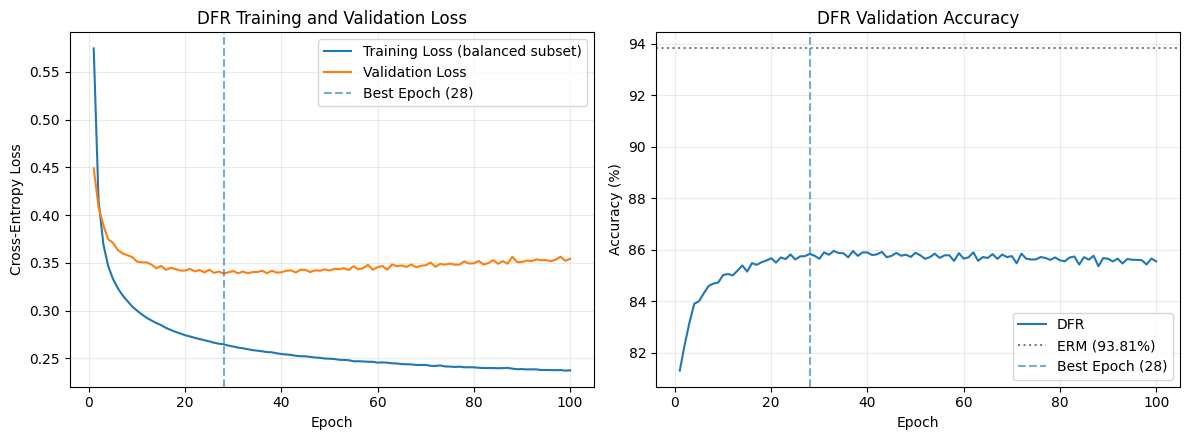

In [5]:
# ============================================================
# 7.6 Visualize DFR training performance
# ============================================================

epochs = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(epochs, dfr_history["train_loss"], label="Training Loss (balanced subset)")
axes[0].plot(epochs, dfr_history["val_loss"], label="Validation Loss")
axes[0].axvline(dfr_best_epoch, linestyle="--", alpha=0.6,
                label=f"Best Epoch ({dfr_best_epoch})")
axes[0].set_title("DFR Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(epochs, dfr_history["val_accuracy"], label="DFR")
axes[1].axhline(erm_val["overall_accuracy"], color="gray", linestyle=":",
                label=f"ERM ({erm_val['overall_accuracy']:.2f}%)")
axes[1].axvline(dfr_best_epoch, linestyle="--", alpha=0.6,
                label=f"Best Epoch ({dfr_best_epoch})")
axes[1].set_title("DFR Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
fig.savefig(FIGURE_DIR / "dfr_training_curves.png", dpi=300, bbox_inches="tight")
plt.show()

### 7.7 Hyperparameter Selection on Validation Worst-Group Accuracy

Following the original DFR, the regularization strength is chosen by **validation worst-group accuracy** (this uses validation group labels, consistent with DFR being a group-aware method). We search weight decay × feature standardization, averaging over the three evaluation seeds. The test set is not used here.

                         val_overall_accuracy       val_worst_group_accuracy      
                                         mean   std                     mean   std
standardize weight_decay                                                          
False       0.0000                      88.21  0.43                    75.82  1.65
            0.0001                      88.22  0.43                    75.82  1.65
            0.0010                      88.21  0.44                    75.64  1.68
            0.0100                      88.08  0.36                    75.27  2.52
            0.1000                      87.96  0.34                    69.96  0.84
            1.0000                      88.39  0.11                    56.59  1.10
True        0.0000                      86.17  0.38                    80.22  1.10
            0.0001                      86.17  0.38                    80.22  1.10
            0.0010                      86.18  0.36                    80.59  1.27
    

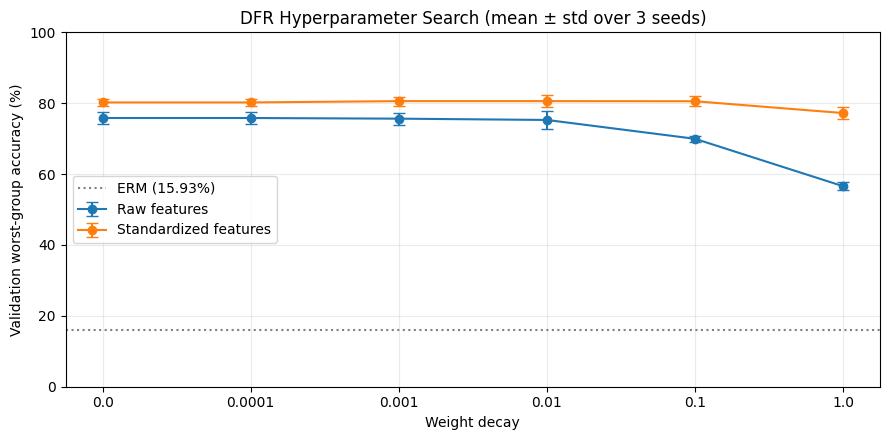

In [6]:
# ============================================================
# 7.7 Hyperparameter search (validation only)
# ============================================================

search_rows = []
start = time.perf_counter()

for standardize in STANDARDIZE_GRID:
    for weight_decay in WEIGHT_DECAY_GRID:
        for seed in EVAL_SEEDS:
            model, mean, std, _, best_epoch = train_dfr(
                balanced_indices(seed), seed, weight_decay, standardize
            )
            result = evaluate(model, X_val, y_val, g_val, mean, std)
            search_rows.append({
                "standardize": standardize,
                "weight_decay": weight_decay,
                "seed": seed,
                "best_epoch": best_epoch,
                "val_overall_accuracy": result["overall_accuracy"],
                "val_worst_group_accuracy": result["worst_group_accuracy"],
            })

search_time = time.perf_counter() - start
search_df = pd.DataFrame(search_rows)

search_summary = (
    search_df.groupby(["standardize", "weight_decay"])
    [["val_overall_accuracy", "val_worst_group_accuracy"]]
    .agg(["mean", "std"])
    .round(2)
)

best_config = (
    search_df.groupby(["standardize", "weight_decay"])
    ["val_worst_group_accuracy"].mean().idxmax()
)
BEST_STANDARDIZE, BEST_WEIGHT_DECAY = bool(best_config[0]), float(best_config[1])

print(search_summary.to_string())
print(f"\nSearch time: {search_time:.1f} seconds")
print(f"Selected: standardize={BEST_STANDARDIZE}, weight_decay={BEST_WEIGHT_DECAY}")

# ------------------------------------------------------------
# Visualize the search
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 4.5))
for standardize, label in [(False, "Raw features"), (True, "Standardized features")]:
    subset = search_df[search_df["standardize"] == standardize]
    stats = subset.groupby("weight_decay")["val_worst_group_accuracy"].agg(["mean", "std"])
    x = np.arange(len(stats))
    ax.errorbar(x, stats["mean"], yerr=stats["std"], marker="o", capsize=4, label=label)

ax.axhline(erm_val["worst_group_accuracy"], color="gray", linestyle=":",
           label=f"ERM ({erm_val['worst_group_accuracy']:.2f}%)")
ax.set_xticks(np.arange(len(WEIGHT_DECAY_GRID)))
ax.set_xticklabels([str(w) for w in WEIGHT_DECAY_GRID])
ax.set_xlabel("Weight decay")
ax.set_ylabel("Validation worst-group accuracy (%)")
ax.set_title("DFR Hyperparameter Search (mean ± std over 3 seeds)")
ax.set_ylim(0, 100)
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
fig.savefig(FIGURE_DIR / "dfr_hparam_search.png", dpi=300, bbox_inches="tight")
plt.show()

### 7.8 Final Multi-Seed Evaluation (Validation and Test)

With hyperparameters fixed, evaluate two variants over seeds 42 / 123 / 2026:

- **DFR (single subset):** one balanced subset per seed.
- **DFR (10-subset ensemble):** as in the original paper, train heads on 10 independent balanced subsets and **average their weights**. All heads share the standardization statistics of the full training split so their weights live in the same space.

This is the first and only time the test set is used.

In [7]:
# ============================================================
# 7.8 Final multi-seed evaluation
# ============================================================

if BEST_STANDARDIZE:
    shared_mean = X_train.mean(axis=0)
    shared_std = X_train.std(axis=0) + 1e-8
else:
    shared_mean, shared_std = None, None

final_rows, group_rows = [], []
final_models = {}


def record(method, seed, model, mean, std, seconds):
    for split, (X, y, g) in {"val": (X_val, y_val, g_val),
                              "test": (X_test, y_test, g_test)}.items():
        result = evaluate(model, X, y, g, mean, std)
        final_rows.append({
            "method": method, "seed": seed, "split": split,
            "overall_accuracy": result["overall_accuracy"],
            "worst_group_accuracy": result["worst_group_accuracy"],
            "worst_group": result["worst_group"],
            "training_time_seconds": seconds,
        })
        for k, acc in result["group_accuracies"].items():
            group_rows.append({"method": method, "seed": seed, "split": split,
                               "group": k, "accuracy": acc})


for seed in EVAL_SEEDS:
    # --- Single balanced subset ---
    start = time.perf_counter()
    model, mean, std, _, _ = train_dfr(
        balanced_indices(seed), seed, BEST_WEIGHT_DECAY, BEST_STANDARDIZE
    )
    record("DFR (single subset)", seed, model, mean, std,
           time.perf_counter() - start)

    # --- Ensemble of balanced subsets (weight averaging) ---
    start = time.perf_counter()
    weights, biases = [], []
    for k in range(N_ENSEMBLE):
        sub_seed = seed * 100 + k
        head, mean, std, _, _ = train_dfr(
            balanced_indices(sub_seed), sub_seed, BEST_WEIGHT_DECAY,
            BEST_STANDARDIZE, mean=shared_mean, std=shared_std,
        )
        weights.append(head.weight.detach())
        biases.append(head.bias.detach())

    ensemble = nn.Linear(512, 2).to(device)
    ensemble.load_state_dict({
        "weight": torch.stack(weights).mean(0),
        "bias": torch.stack(biases).mean(0),
    })
    record("DFR (10-subset ensemble)", seed, ensemble, mean, std,
           time.perf_counter() - start)
    final_models[seed] = (ensemble, mean, std)

# ERM reference rows (multi-seed, trained in 7.3)
for seed in EVAL_SEEDS:
    for split in ("val", "test"):
        result = erm_runs[seed][split]
        final_rows.append({
            "method": "ERM", "seed": seed, "split": split,
            "overall_accuracy": result["overall_accuracy"],
            "worst_group_accuracy": result["worst_group_accuracy"],
            "worst_group": result["worst_group"],
            "training_time_seconds": erm_runs[seed]["seconds"],
        })
        for k, acc in result["group_accuracies"].items():
            group_rows.append({"method": "ERM", "seed": seed, "split": split,
                               "group": k, "accuracy": acc})

final_df = pd.DataFrame(final_rows)
group_df = pd.DataFrame(group_rows)

final_summary = (
    final_df.groupby(["method", "split"], sort=False)
    [["overall_accuracy", "worst_group_accuracy", "training_time_seconds"]]
    .agg(["mean", "std"])
    .round(2)
)
print(final_summary.to_string())

                               overall_accuracy       worst_group_accuracy       training_time_seconds      
                                           mean   std                 mean   std                  mean   std
method                   split                                                                              
DFR (single subset)      val              86.18  0.36                80.59  1.27                  1.04  0.25
                         test             87.11  0.12                78.33  3.09                  1.04  0.25
DFR (10-subset ensemble) val              85.14  0.03                81.32  0.20                 10.23  0.07
                         test             86.42  0.01                81.85  0.85                 10.23  0.07
ERM                      val              93.81  0.01                15.93  0.55                 40.56  0.90
                         test             94.26  0.03                20.00  0.56                 40.56  0.90


### 7.9 Ablation: Is It Balancing or Standardization?

DFR changes two things relative to our ERM baseline: the **training data** (group-balanced) and, if selected, the **feature standardization**. To attribute the improvement, we train ERM on the *full* training set with standardized features and otherwise identical settings.

In [8]:
# ============================================================
# 7.9 Ablation: ERM with standardized features
# ============================================================

start = time.perf_counter()
erm_std_model, m, s, _, erm_std_epoch = train_dfr(
    np.arange(len(y_train)), SEED, weight_decay=1e-4,
    standardize=True, epochs=20,
)
erm_std_time = time.perf_counter() - start
erm_std_val = evaluate(erm_std_model, X_val, y_val, g_val, m, s)

ablation_df = pd.DataFrame([
    {"Model": "ERM (raw features, seed 42)", "Training data": "Full",
     "Overall (%)": erm_runs[SEED]["val"]["overall_accuracy"],
     "Worst-group (%)": erm_runs[SEED]["val"]["worst_group_accuracy"]},
    {"Model": "ERM (standardized features, seed 42)", "Training data": "Full",
     "Overall (%)": erm_std_val["overall_accuracy"],
     "Worst-group (%)": erm_std_val["worst_group_accuracy"]},
    {"Model": "DFR (single subset, seed 42)", "Training data": "Group-balanced",
     "Overall (%)": final_df.query("method == 'DFR (single subset)' and seed == 42 and split == 'val'")["overall_accuracy"].item(),
     "Worst-group (%)": final_df.query("method == 'DFR (single subset)' and seed == 42 and split == 'val'")["worst_group_accuracy"].item()},
]).round(2)

print("Validation results")
print(ablation_df.to_string(index=False))

Validation results
                               Model  Training data  Overall (%)  Worst-group (%)
         ERM (raw features, seed 42)           Full        93.81            16.48
ERM (standardized features, seed 42)           Full        93.82            18.13
        DFR (single subset, seed 42) Group-balanced        85.84            81.32


### 7.10 Group-Wise Comparison with ERM

Per-group validation accuracy of ERM versus the DFR ensemble (mean over seeds, error bars = std).

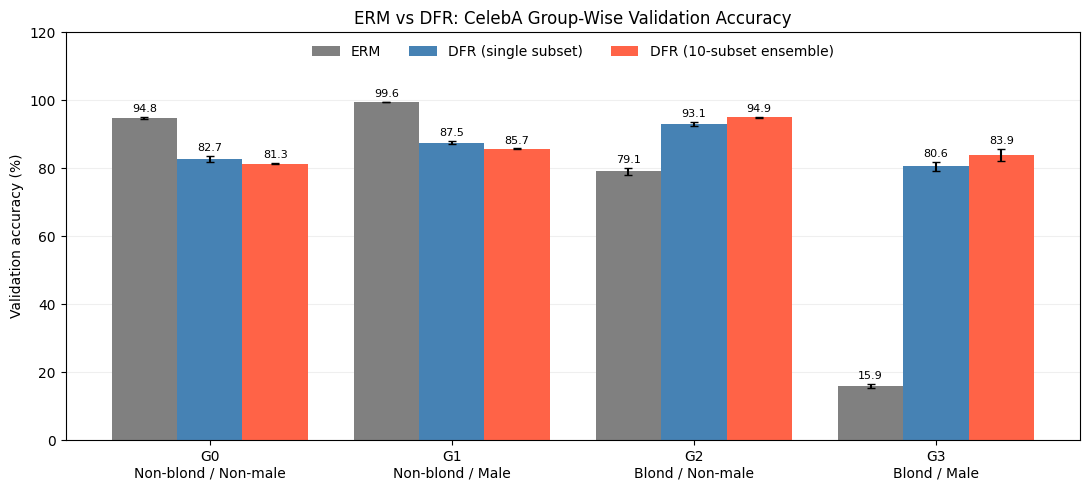

In [9]:
# ============================================================
# 7.10 Group-wise comparison visualization
# ============================================================

val_groups = group_df[group_df["split"] == "val"]
methods = ["ERM", "DFR (single subset)", "DFR (10-subset ensemble)"]
colors = ["gray", "steelblue", "tomato"]

group_summary = (
    val_groups.groupby(["method", "group"])["accuracy"]
    .agg(["mean", "std"]).fillna(0)
)

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(4)
width = 0.27

for i, (method, color) in enumerate(zip(methods, colors)):
    stats = group_summary.loc[method]
    bars = ax.bar(x + (i - 1) * width, stats["mean"], width,
                  yerr=stats["std"], capsize=3, color=color, label=method)
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels([f"G{k}\n{GROUP_NAMES[k]}" for k in range(4)])
ax.set_ylabel("Validation accuracy (%)")
ax.set_title("ERM vs DFR: CelebA Group-Wise Validation Accuracy")
ax.set_ylim(0, 120)
ax.legend(loc="upper center", ncol=3, frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
fig.savefig(FIGURE_DIR / "dfr_group_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()

### 7.11 Save DFR Results

Save metrics, per-group accuracies, the hyperparameter search, the seed-42 training history, and the seed-42 ensemble checkpoint (`results/models/dfr_celeba.pt`, not tracked by Git; regenerate by running this notebook).

In [10]:
# ============================================================
# 7.11 Save DFR results
# ============================================================

pd.DataFrame({
    "epoch": range(1, EPOCHS + 1), **dfr_history
}).to_csv(METRICS_DIR / "dfr_celeba_history.csv", index=False)

search_df.to_csv(METRICS_DIR / "dfr_hparam_search.csv", index=False)
final_df.to_csv(METRICS_DIR / "dfr_multiseed.csv", index=False)
group_df.to_csv(METRICS_DIR / "dfr_group_accuracy.csv", index=False)
ablation_df.to_csv(METRICS_DIR / "dfr_ablation.csv", index=False)


def summarize(method, split):
    rows = final_df[(final_df["method"] == method) & (final_df["split"] == split)]
    groups = group_df[(group_df["method"] == method) & (group_df["split"] == split)]
    return {
        "overall_accuracy_mean": float(rows["overall_accuracy"].mean()),
        "overall_accuracy_std": float(rows["overall_accuracy"].std(ddof=1)),
        "worst_group_accuracy_mean": float(rows["worst_group_accuracy"].mean()),
        "worst_group_accuracy_std": float(rows["worst_group_accuracy"].std(ddof=1)),
        "group_accuracies_mean": {
            str(k): float(v) for k, v in groups.groupby("group")["accuracy"].mean().items()
        },
        "training_time_seconds_mean": float(rows["training_time_seconds"].mean()),
    }


experiment_results = {
    "experiment": "DFR (Deep Feature Reweighting), last-layer retraining on group-balanced training subset",
    "dataset": "CelebA",
    "target": "Blond_Hair",
    "spurious_attribute": "Male",
    "uses_group_labels": True,
    "feature_extractor": "ImageNet ResNet-18 (frozen)",
    "classifier": "Linear(512, 2)",
    "retraining_data": "group-balanced subset of the training split",
    "examples_per_group": N_PER_GROUP,
    "balanced_subset_size": 4 * N_PER_GROUP,
    "seeds": EVAL_SEEDS,
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "checkpoint_selection": "minimum validation loss",
    "hyperparameter_selection": "mean validation worst-group accuracy over seeds",
    "selected_weight_decay": BEST_WEIGHT_DECAY,
    "selected_standardize": BEST_STANDARDIZE,
    "n_ensemble": N_ENSEMBLE,
    "results": {
        method: {split: summarize(method, split) for split in ("val", "test")}
        for method in ["ERM", "DFR (single subset)", "DFR (10-subset ensemble)"]
    },
    "erm_reference": "retrained here for each seed with the epic_celeba.ipynb 3.9 multi-seed ERM procedure",
    "ablation_erm_standardized_val": erm_std_val,
}

with open(METRICS_DIR / "dfr_celeba.json", "w") as f:
    json.dump(experiment_results, f, indent=4)

ensemble, mean, std = final_models[SEED]
torch.save({
    "model_state_dict": ensemble.state_dict(),
    "feature_mean": torch.from_numpy(np.asarray(mean, dtype=np.float32)),
    "feature_std": torch.from_numpy(np.asarray(std, dtype=np.float32)),
    "seed": SEED,
    "weight_decay": BEST_WEIGHT_DECAY,
    "standardize": BEST_STANDARDIZE,
    "n_ensemble": N_ENSEMBLE,
}, MODEL_DIR / "dfr_celeba.pt")

print("Saved:")
for path in sorted(METRICS_DIR.glob("dfr_*")) + sorted(FIGURE_DIR.glob("dfr_*")):
    print(f"  {path}")
print(f"  {MODEL_DIR / 'dfr_celeba.pt'} (local only)")

Saved:
  results\metrics\dfr_ablation.csv
  results\metrics\dfr_celeba.json
  results\metrics\dfr_celeba_history.csv
  results\metrics\dfr_group_accuracy.csv
  results\metrics\dfr_hparam_search.csv
  results\metrics\dfr_multiseed.csv
  results\figures\dfr_group_accuracy.png
  results\figures\dfr_hparam_search.png
  results\figures\dfr_training_curves.png
  results\models\dfr_celeba.pt (local only)


### 7.12 Results Summary

Validation and test results, mean ± std over seeds 42 / 123 / 2026 for every method:

| Method | Group labels? | Val overall | Val WGA | Test overall | Test WGA | Training cost |
|---|---|---:|---:|---:|---:|---:|
| ERM | No | 93.81 ± 0.01 | 15.93 ± 0.55 | 94.26 ± 0.03 | 20.00 ± 0.56 | ~39 s (full train set, 20 epochs) |
| DFR (single subset) | Yes | 86.18 ± 0.36 | 80.59 ± 1.27 | 87.11 ± 0.12 | 78.33 ± 3.09 | ~1 s |
| DFR (10-subset ensemble) | Yes | 85.14 ± 0.03 | 81.32 ± 0.20 | 86.42 ± 0.01 | 81.85 ± 0.85 | ~10 s |

The ERM row is retrained here with the `epic_celeba.ipynb` multi-seed procedure and matches the team reference (validation 93.81 ± 0.01% overall, 15.75 ± 0.32% WGA) to within one G3 example. All costs exclude the one-time ResNet-18 feature extraction shared by every method.

**Findings**

1. **The frozen representation already separates the minority group.** Retraining only the last layer on 5,548 group-balanced examples (3.4% of the training data) raises worst-group accuracy from 15.9% to 81.3% on validation and from 20.0% to 81.9% on test. ERM's failure on Blond / Male is therefore mostly a *classifier-head* problem, not a missing-feature problem, which is the central claim of DFR.
2. **Balancing, not preprocessing, drives the gain.** Standardizing features for ERM on the full training set moves seed-42 validation WGA only from 16.48% to 18.13% (7.9). Standardization does help *within* DFR (≈ +5 points WGA over raw features, 7.7), and the result is insensitive to weight decay between 0 and 0.1.
3. **Robustness costs average accuracy.** Overall accuracy drops from 93.81% to ~86%, because the head no longer exploits the `Male → Non-blond` shortcut that helps the large groups G0 and G1 (99.6% → ~86% on G1), while G2 and G3 improve sharply.
4. **Ensembling mainly reduces variance.** Averaging 10 balanced heads gives similar mean WGA to a single subset but much smaller seed-to-seed spread (test WGA std 0.85 vs 3.09), at 10× the (still tiny) cost.

**Caveats.** DFR uses group labels to build the balanced subset and to choose hyperparameters, so it should be compared with Group DRO rather than with the group-agnostic methods (ERM, EPIC-inspired, random filtering, JTT). Our backbone is ImageNet-pretrained and never fine-tuned on CelebA, so these numbers are not directly comparable with the published DFR results, which retrain the last layer of a CelebA-trained ERM network on validation data.